<a name="top" id="top"></a>

**Big idea of this notebook:** a colour image is **3 grids of numbers stacked together** (Red, Green, Blue).
We split those grids apart, and then we write our **own filter** with plain Python loops: a small window
slides over the image, takes the **average** of the pixels under it, and jumps forward by a **stride**.

Writing it by hand shows exactly what OpenCV / TensorFlow do inside their one-line functions — and it is the
same sliding-window idea that a CNN layer uses

---

### 📚 Table of Contents
1. [Load and display a colour image](#s1)
2. [Split the image into R, G, B channels](#s2)
3. [Write our own filter (sliding window + stride)](#s3)
4. [Apply the filter with window sizes 3, 11 and 25](#s4)
5. [Check the output-size formula and compare with OpenCV](#s5)
6. [Summary and key takeaways](#s6)


<a name="s1" id="s1"></a>

## 1. Load and display a colour image

[⬆ Back to top](#top)

**What this section does:** We read a colour image into a NumPy array and print its shape `(rows, columns, channels)`.

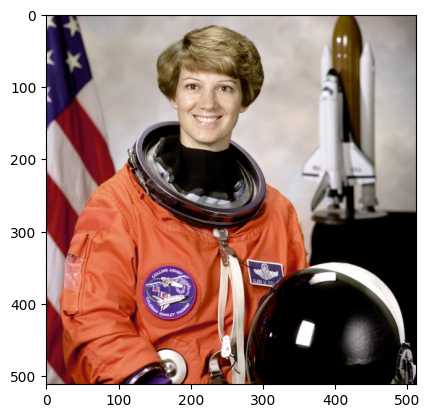

In [16]:
# Import scikit-image's I/O module, Matplotlib and NumPy; load a 512x512 colour image and show it.
# skimage.io.imread returns the image in R,G,B order (unlike OpenCV, which uses B,G,R),
#       so Matplotlib shows the colours correctly without any conversion.
# 🔧 Fixed: the original read 'lena.jpg', which is not provided (and the "Lena" picture is no longer
#    recommended for teaching/publications). We use skimage's built-in 'astronaut' image (also 512x512x3).
#    To use your own file instead: upload it to Colab and write  img = io.imread('your_file.jpg')
import skimage.io as io
from skimage import data
import matplotlib.pyplot as plt
import numpy as np

# Read the image
img = data.astronaut()          # original: img = io.imread('lena.jpg')

plt.imshow(img)
plt.show()

In [17]:
# Print the shape of the image array.
# (512, 512, 3) -> 512 rows, 512 columns, 3 channels (R, G, B). Total numbers = 512*512*3 = 786,432.
img.shape

(512, 512, 3)

<a name="s2" id="s2"></a>

## 2. Split the image into R, G, B channels

[⬆ Back to top](#top)

**What this section does:** We cut the 3-D array into three 2-D arrays — one per colour — and look at each one.

In [18]:
# Take channel 0, 1 and 2 out of the 3-D array.
# img[:, :, 0] means "all rows, all columns, channel 0" -> a 512x512 grid of RED intensities.
# Split
red = img[:, :, 0]
green = img[:, :, 1]
blue = img[:, :, 2]

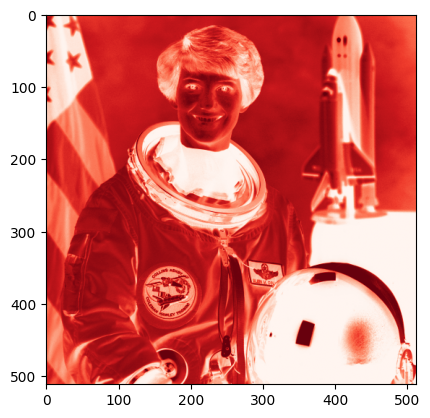

In [19]:
# Show the red channel with the "Reds" colour map.
# Each channel is just a grey-level grid; the colour map paints low values light and high values dark red.
#       The orange suit and the skin contain a lot of red, so they look strongest here.

plt.imshow(red, cmap="Reds")
plt.show()

**Brief note on how "cmap" works**

There are predefined color anchors for each cmap in RGB format - For example "Blues" (two cells below this one) has this
$$
\begin{array}{c|c}
\text{position} & (R,G,B) \\ \hline
0.00 & (247, 251, 255) \\
0.25 & (198, 219, 239) \\
0.50 & (107, 174, 214) \\
0.75 & (33, 113, 181) \\
1.00 & (8, 48, 107)
\end{array}
$$

Each of the pixel goes through the these stesp:
- normalize pixel values between 0 to 1 by dividing by 255
- find which two anchors the norm-pixel falls between
- calculate how far they are from the anchor points (weight)
- then use that weight to find the values for each of R,G and B (filling the gap between two known anchors — is the interpolation)

Worked example — norm-pixel = 0.59

It sits between anchors $a = 0.50$ and $b = 0.75$. Find how far along:

$$t = \frac{0.59 - 0.50}{0.75 - 0.50} = \frac{0.09}{0.25} = 0.36$$

Blend each channel ($C = C_a + t(C_b - C_a)$):

$$
\begin{aligned}
R &= 107 + 0.36(33 - 107) = 107 - 26.6 \approx 80 \\
G &= 174 + 0.36(113 - 174) = 174 - 22.0 \approx 152 \\
B &= 214 + 0.36(181 - 214) = 214 - 11.9 \approx 202
\end{aligned}
$$
$$f_{Blues}(0.59) \approx (80,\, 152,\, 202)$$

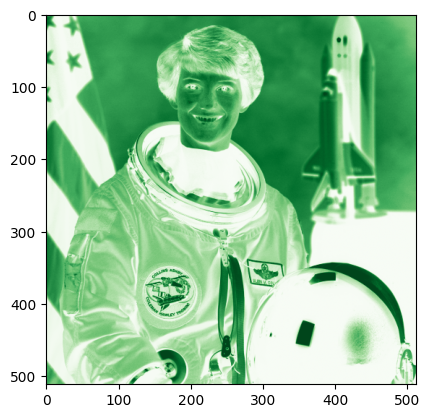

In [20]:
plt.imshow(green, cmap="Greens")
plt.show()

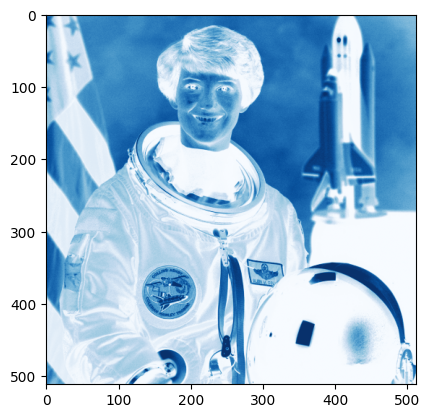

In [21]:
# Show the blue channel with the "Blues" colour map.
# Orange has very little blue, so the suit is much weaker here than in the red channel;
plt.imshow(blue, cmap="Blues")
plt.show()

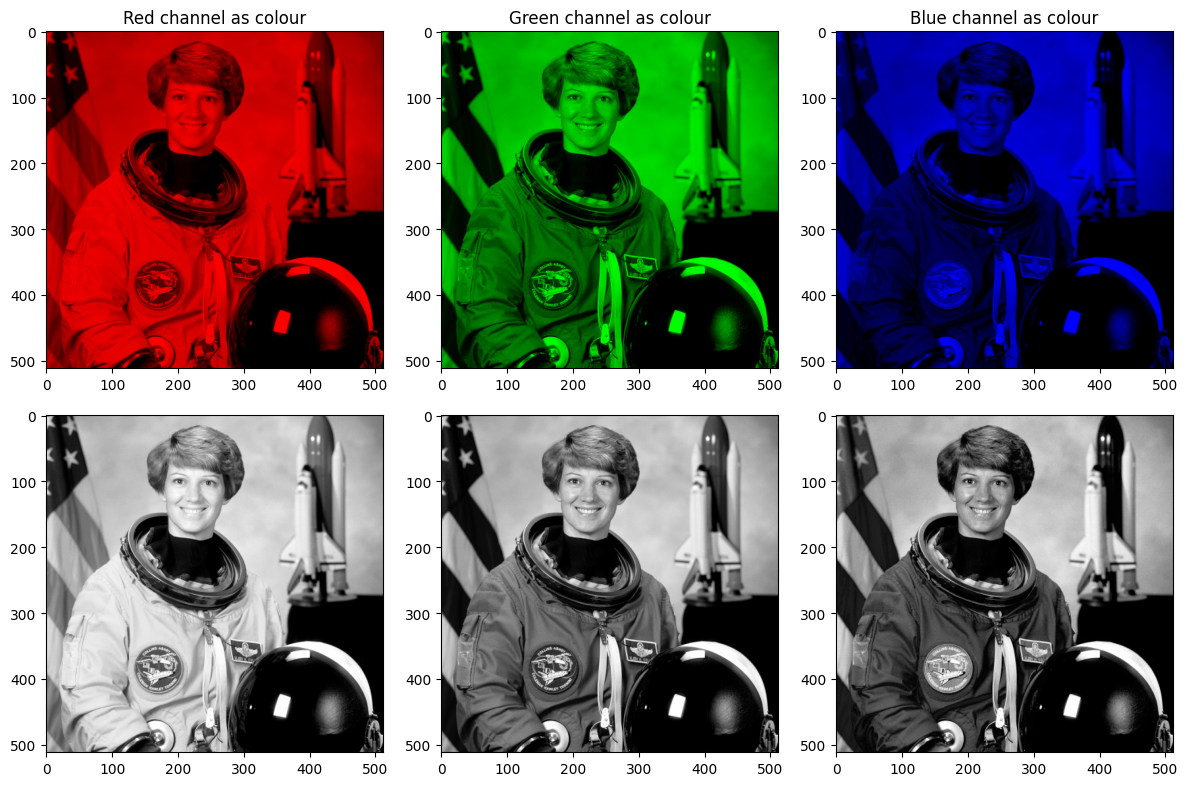

Pixel at row 100, col 200 (R, G, B): [81 57 17]


In [22]:
# show each channel as a real colour image (keep one channel, set the other two to 0),
#       next to the same channel shown in plain grey.
# Avoids a common confusion: a channel is NOT a coloured picture, it is only a grid of numbers.
#       The colour you "see" depends on how we choose to display those numbers.
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for i, name in enumerate(['Red', 'Green', 'Blue']):
    only = np.zeros_like(img)
    only[:, :, i] = img[:, :, i]          # keep channel i, others stay 0
    ax[0, i].imshow(only)
    ax[0, i].set_title(f'{name} channel as colour')
    ax[1, i].imshow(img[:, :, i], cmap='gray')  # we choose to display these numbers as grayscale
    # ax[1, i].set_title(f'{name} channel as grey (0-255)')
    # ax[0, i].axis('off'); ax[1, i].axis('off')
plt.tight_layout(); plt.show()
print('Pixel at row 100, col 200 (R, G, B):', img[100, 200])

<a name="s3" id="s3"></a>

## 3. Write our own filter (sliding window + stride)

[⬆ Back to top](#top)

**What this section does:** We define `filtering(img, f)` — a **mean (box) filter with stride 2**:
1. Put an $f \times f$ window on the top-left corner of one channel.
2. Replace the whole window by **one number: the average** of its pixels.
3. Jump **2 pixels** (the *stride*) to the right; at the end of the row jump 2 pixels down.
4. Do this for every channel.

Because the window jumps by 2, the output is about **half the size**. The output size is

$$n_{out} = \left\lfloor \frac{n - f}{s} \right\rfloor + 1$$

In [23]:
# Define the hand-written filter function (mean of each f x f window, stride 2).
# 3 nested loops makes the sliding-window idea concrete:
#       h, w = position of the window in the OUTPUT; c = colour channel.
#       vert_start = h*stride, horiz_start = w*stride -> where the window sits in the INPUT.
def filtering(img, f=3):

    # Dimensions from the input shape
    (rows, col, channels) = img.shape

    # Initialize "hyper parameters"
    stride = 2

    # Dimensions of the output:  floor((n - f) / s) + 1
    n_rows = int(1 + (rows - f) / stride)
    n_col = int(1 + (col - f) / stride)
    n_channels = channels

    # Initialize output matrix
    n_img = np.zeros((n_rows, n_col, n_channels))

    # print(f"n_img: {n_img.shape}")
    # print(f"n_rows: {n_rows}")
    # print(f"n_col: {n_col}")
    # print(f"n_channels: {n_channels}")
    # print(f"f: {f}")
    # print(f"stride: {stride}")
    # iterate through img
    for h in range(n_rows):
        for w in range(n_col):
            for c in range(n_channels):

                # print(f"n_rows: {h}")
                # print(f"n_col: {w}")
                # print(f"n_channels: {c}")

                vert_start = h * stride
                # print(f"vert_start: {vert_start}")
                vert_end = vert_start + f
                # print(f"vert_end: {vert_end}")
                horiz_start = w * stride
                # print(f"horiz_start: {horiz_start}")

                horiz_end = horiz_start + f
                # print(f"horiz_end: {horiz_end}")

                # extract the f x f slice we are dealing with
                n_slice = img[vert_start:vert_end, horiz_start:horiz_end, c]
                # print(f"n_slice: \n{n_slice}")

                # Compute the filtering operation on the slice (average, kept as a whole number)
                # print(f"n_img[h, w, c]: {n_img[h, w, c]}")

                n_img[h, w, c] = np.mean(n_slice, dtype=int)
    return n_img

<a name="s4" id="s4"></a>

## 4. Apply the filter with window sizes 3, 11 and 25

[⬆ Back to top](#top)

**What this section does:** Bigger window → each output pixel is the average of **more** pixels → **more blur**.
The output size also shrinks a little as $f$ grows (255 → 251 → 244).

(255, 255, 3)


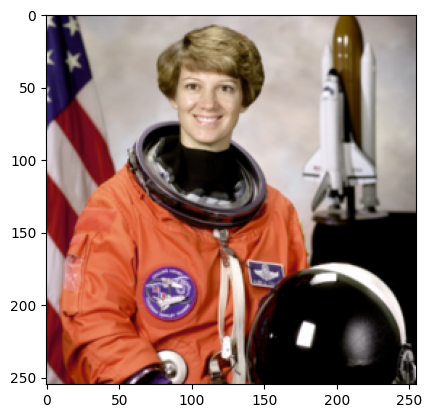

In [24]:
# Filter with a 3x3 window and show the result.
# Output size = floor((512 - 3)/2) + 1 = 254 + 1 = 255  ->  (255, 255, 3).
#    everything above 1 -> the picture came out almost white / wrong colours. We convert to uint8 to display.
A = filtering(img)
print(A.shape)
plt.imshow(A.astype('uint8'))
plt.show()

(251, 251, 3)


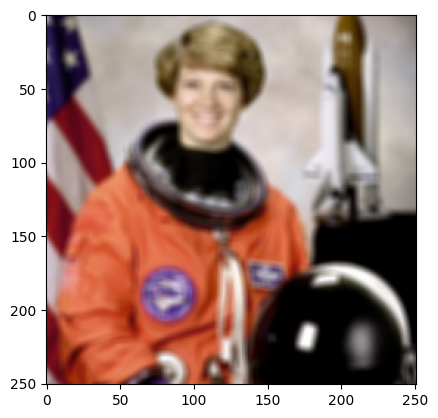

In [25]:
# Filter with an 11x11 window.
# Output size = floor((512 - 11)/2) + 1 = 250 + 1 = 251. Visibly blurrier than f = 3.
A = filtering(img, f=11)
print(A.shape)
plt.imshow(A.astype('uint8'))
plt.show()

(244, 244, 3)


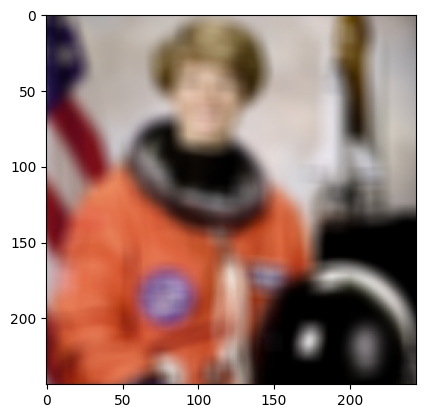

In [26]:
# Filter with a 25x25 window.
# Output size = floor((512 - 25)/2) + 1 = 243 + 1 = 244. Each output pixel now averages 625 pixels -> strong blur.
A = filtering(img, f=25)
print(A.shape)
plt.imshow(A.astype('uint8'))
plt.show()

<a name="s5" id="s5"></a>

## 5. Check the output-size formula and compare with OpenCV

[⬆ Back to top](#top)

**What this section does:** Two quick checks: (a) the formula $\lfloor (n-f)/s \rfloor + 1$ predicts every output size;
(b) OpenCV's built-in `cv2.blur` does the same averaging in one line (it keeps the full size, so we take
every 2nd pixel to imitate stride 2).

In [27]:
# compute the predicted output size for f = 3, 11, 25 with the formula.
# Shows the formula and the code agree, before we meet the same formula for CNN layers.
n, s = 512, 2
for f in [3, 11, 25]:
    print(f'f = {f:2d}:  floor(({n} - {f}) / {s}) + 1 = {(n - f) // s + 1}')

f =  3:  floor((512 - 3) / 2) + 1 = 255
f = 11:  floor((512 - 11) / 2) + 1 = 251
f = 25:  floor((512 - 25) / 2) + 1 = 244


In [28]:
# the same 3x3 mean filter using OpenCV, then keep every 2nd pixel (stride 2).
# cv2.blur centres the window on each pixel, so [1::2, 1::2] picks the window centres our loop used.
#       The tiny difference left is only rounding (np.mean(dtype=int) drops decimals; cv2.blur rounds).
import cv2
fast = cv2.blur(img, (3, 3))[1:-1:2, 1:-1:2]
slow = filtering(img, f=3)
print('shapes:', fast.shape, slow.shape)
print('largest difference between the two results:', np.abs(fast.astype(int) - slow.astype(int)).max(), 'grey levels')

shapes: (255, 255, 3) (255, 255, 3)
largest difference between the two results: 1 grey levels


<a name="s6" id="s6"></a>

## 6. Summary and key takeaways

[⬆ Back to top](#top)

- A colour image = 3 stacked 2-D grids (R, G, B). Shape `(rows, cols, 3)`.
- A channel on its own is just numbers 0–255; the colour shown is only a display choice (colour map).
- A **filter** slides a small window over the image; a **mean filter** replaces each window by its average → blur.
- **Window size $f$** controls how much blur; **stride $s$** controls how far the window jumps (and how much the image shrinks).
- Output size: $n_{out} = \lfloor (n - f)/s \rfloor + 1$ → 255, 251, 244 for $f$ = 3, 11, 25.
- CNN layers use exactly this sliding window — but the weights inside the window are **learned**, not fixed to $1/f^2$.